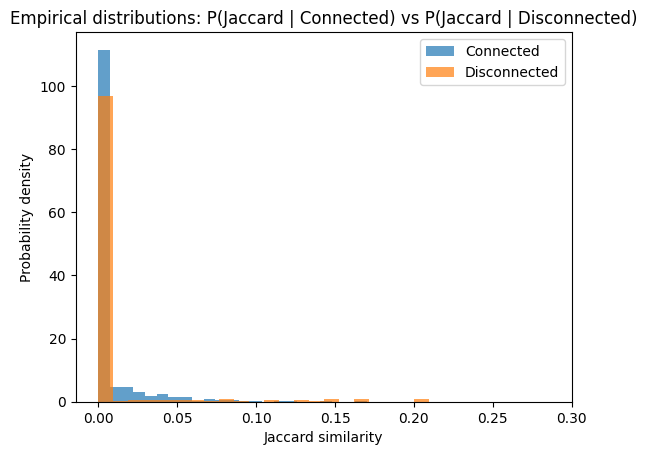

Graph-level priors:
  P(Connected)    ~= 5.987988e-03
  P(Disconnected) ~= 9.940120e-01
  Prior ratio P(Disconn)/P(Conn) ~= 1.660e+02
JACC: total error rate = 0.4998 | predicted connected = 1 / 4,000
AA  : total error rate = 0.4888 | predicted connected = 45 / 4,000


In [ ]:
import networkx as nx
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(2)
np.random.seed(2)

n = 1000
m_param = 3
G = nx.barabasi_albert_graph(n=n, m=m_param, seed=0)

nodes = list(G.nodes())
degrees = dict(G.degree())
neighbors = {u: set(G.neighbors(u)) for u in nodes}

def compute_similarity(i, j):
    """function to return both Jacc and Adamic"""

    Ni = neighbors[i]
    Nj = neighbors[j]

    common = Ni & Nj
    union = Ni | Nj

    jacc = len(common) / len(union) if union else 0.0

    aa = 0.0
    for k in common:
        dk = degrees[k]
        if dk > 1:
            aa += 1.0 / np.log(dk)

    return jacc, aa
"""need sample data so took here. Most of the code here was minorly edited from provided class notes"""

N_POS = 2000
N_NEG = 2000

edges = list(G.edges())
connected_pairs = random.sample(edges, min(N_POS, len(edges)))

disconnected_pairs = set()
while len(disconnected_pairs) < N_NEG:
    i, j = random.sample(nodes, 2)
    if i == j:
        continue
    if i > j:
        i, j = j, i
    if not G.has_edge(i, j):
        disconnected_pairs.add((i, j))
disconnected_pairs = list(disconnected_pairs)

connected_jaccard, connected_aa = [], []
disconnected_jaccard, disconnected_aa = [], []

for (i, j) in connected_pairs:
    jacc, aa = compute_similarity(i, j)
    connected_jaccard.append(jacc)
    connected_aa.append(aa)

for (i, j) in disconnected_pairs:
    jacc, aa = compute_similarity(i, j)
    disconnected_jaccard.append(jacc)
    disconnected_aa.append(aa)

plt.figure()
plt.hist(connected_jaccard, bins=30, density=True, alpha=0.7, label="Connected")
plt.hist(disconnected_jaccard, bins=30, density=True, alpha=0.7, label="Disconnected")
plt.xlabel("Jaccard similarity")
plt.ylabel("Probability density")
plt.title("Empirical distributions: P(Jaccard | Connected) vs P(Jaccard | Disconnected)")
plt.legend()
plt.show()


n_nodes = G.number_of_nodes()
m_edges = G.number_of_edges()
p_conn = m_edges / (n_nodes * (n_nodes - 1) / 2)
p_disc = 1.0 - p_conn

print("Graph-level priors:")
print(f"  P(Connected)    ~= {p_conn:.6e}")
print(f"  P(Disconnected) ~= {p_disc:.6e}")
print(f"  Prior ratio P(Disconn)/P(Conn) ~= {p_disc/p_conn:.3e}")


def fit_hist_density(scores_pos, scores_neg, bins=50, eps=1e-12):
    """Fit histogram-based densities p(s|Conn) and p(s|Disc) on a shared binning."""
    scores_pos = np.asarray(scores_pos, dtype=float)
    scores_neg = np.asarray(scores_neg, dtype=float)

    scores_all = np.concatenate([scores_pos, scores_neg])
    lo, hi = float(scores_all.min()), float(scores_all.max())
    if lo == hi:
        hi = lo + 1e-9

    p_s_conn, bin_edges = np.histogram(scores_pos, bins=bins, range=(lo, hi), density=True)
    p_s_disc, _         = np.histogram(scores_neg, bins=bins, range=(lo, hi), density=True)

    p_s_conn = p_s_conn + eps
    p_s_disc = p_s_disc + eps

    return bin_edges, p_s_conn, p_s_disc

def hist_density_eval(score, bin_edges, hist_density):
    idx = np.searchsorted(bin_edges, score, side="right") - 1
    idx = int(np.clip(idx, 0, len(hist_density) - 1))
    return float(hist_density[idx])

def bayes_predict(score, model, p_conn, p_disc):

    bin_edges, p_s_conn, p_s_disc = model
    ls_conn = hist_density_eval(score, bin_edges, p_s_conn)  # ~ p(s|Conn)
    ls_disc = hist_density_eval(score, bin_edges, p_s_disc)  # ~ p(s|Disc)
    return 1 if (ls_conn * p_conn) > (ls_disc * p_disc) else 0

def total_error_rate(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    return float(np.mean(y_true != y_pred))


models = {
    "jacc": fit_hist_density(connected_jaccard, disconnected_jaccard, bins=50),
    "aa":   fit_hist_density(connected_aa, disconnected_aa, bins=60),
}

y_true = np.array([1] * len(connected_pairs) + [0] * len(disconnected_pairs), dtype=int)

scores_all = {
    "jacc": np.array(connected_jaccard + disconnected_jaccard, dtype=float),
    "aa":   np.array(connected_aa + disconnected_aa, dtype=float),
}

for feature in ["jacc", "aa"]:
    scores = scores_all[feature]
    y_pred = np.array([bayes_predict(s, models[feature], p_conn, p_disc) for s in scores], dtype=int)
    err = total_error_rate(y_true, y_pred)
    print(f"{feature.upper():4s}: total error rate = {err:.4f} | predicted connected = {int(y_pred.sum()):,} / {len(y_pred):,}")


P(Connected)≈0.006, the Bayes classifier strongly favors predicting “disconnected” unless the similarity score provides very strong evidence for an edge. This is reflected in the results: both similarity measures predict very few connections overall. Jaccard predicts only 1 connections out of 4000 sampled pairs, while Adamic–Adar predicts 45. Because our evaluation sample is balanced (2000 connected and 2000 disconnected pairs), predicting almost everything as “disconnected” leads to an error rate close to 0.5. Adamic–Adar achieves slightly lower error than Jaccard, indicating that it provides better separation between connected and disconnected pairs in this BA graph.